# LeapQuant 教程 (1/5): 线性注意力的"状态" —— 到底要量化什么

**LeapQuant** (arXiv 2609.38166) 是给线性注意力层 (GDN/KDA) 的**递归状态**做 int8 压缩的算法,
vllm-ascend 里的实现分两个 PR: PR1 纯 torch (本系列), PR2 triton 融合内核 (另见 triton notebook)。

这一本**不谈量化**, 先把被量化的对象讲透: 一个每 token 更新一次的矩阵"账本"。

读完这 5 本你会明白:
1. 状态是什么、怎么更新 (本本);
2. int8 量化误差从哪来、怎么会累积 (2);
3. LeapQuant 量化器为什么比朴素 int8 准 2.4× (3);
4. 窗口机制怎么把误差压成有界平台、window/r 怎么选 (4);
5. 这一切在 vllm-ascend 里怎么接线跑起来 (5)。

前置: 会 python 与张量形状即可。环境: A3 NPU 优先 (自动回退 CPU)。

In [1]:
import sys, math
import torch

sys.path.insert(0, "/workspace/y00924007/vllm-ascend")  # 开发树 (分支 leapquant-triton-m3)

try:
    import torch_npu  # noqa: F401 — 注册 npu 后端
    DEV = torch.device("npu") if torch.npu.is_available() else torch.device("cpu")
except Exception:
    DEV = torch.device("cpu")

import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("vllm").setLevel(logging.ERROR)

torch.manual_seed(20261110)
print(f"torch = {torch.__version__}   device = {DEV}")

torch = 2.10.0+cpu   device = npu


/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


## 1. 为什么要"状态" —— 从注意力说起

Transformer 的 softmax attention 有个工程缺点: 每个 token 都要**回看全部历史** (KV cache),
显存随序列长度线性增长。

线性注意力换了个思路: 把历史**压缩进一个固定大小的矩阵** $S$ —— 一本"记忆账本":

- 每来一个新 token, 对账本做一次**更新** (写);
- 要回忆时, 拿查询向量 $q$ 去"读"账本: $o = S\,q$;
- 账本大小**与序列长度无关** —— 这就是"状态" (recurrent state)。

GDN (Gated DeltaNet) 是 Qwen3-Next / Kimi 等模型用的线性注意力变体。下面先把这本账本
用 4×4 的小矩阵手工玩一遍。

In [3]:
import torch 
k = 4

print(torch.randn(3,k))
print(torch.randn(k))

tensor([[ 1.3486, -0.0336, -1.1401, -0.2187],
        [-0.9372, -0.3979, -1.1098,  1.1504],
        [ 1.6779,  0.4408, -0.8287, -0.1244]])
tensor([-0.0985,  0.3149, -0.7088, -0.4587])


对齐背景：GDN 里面的**关联记忆库（associative memory bank）**底层就是经典的 **Hopfield / Modern Hopfield（现代 Hopfield）** 外积记忆机制，这一段是 GDN 论文 §5 记忆模块的极简教学 demo，把高维记忆矩阵（真实 128×128）压缩成小矩阵方便看懂。

$$核心公式：记忆矩阵 \(S = \sum v_t k_t^\top\)，查询输出 \(o = S q\)，等价于 \(o=\sum (k_t^\top q)\,v_t\)$$

In [2]:
import torch

K, V = 4, 4                      # 教学规模: 键 4 维, 值 4 维 (真实是 128×128, 见 §5)
torch.manual_seed(0)

# 3 个 token: 键 k (编入索引), 值 v (记的内容), 查询 q (读出用)
ks = torch.nn.functional.normalize(torch.randn(3, K), dim=-1)
vs = torch.randn(3, V)
q  = torch.nn.functional.normalize(torch.randn(K), dim=-1)

S = torch.zeros(V, K)
for t in range(3):
    S += torch.outer(vs[t], ks[t])       # 写入: S ← S + v kᵀ (外积)
    print(f"写入 token {t} 后的账本 S:\n{S.numpy().round(2)}\n")

o = S @ q                                # 读出: o = S q
w = ks @ q                               # 每个 token 被读出的权重 = k·q
print("查询 q 与各 k 的相似度 (读出权重):", [f"{x:.2f}" for x in w.tolist()])
print("读出 o =", o.numpy().round(2))
print("加权验证 o ≈ Σ wᵗ·vᵗ:", (w @ vs).numpy().round(2), " ← 账本读出就是按相似度加权取回旧内容")

写入 token 0 后的账本 S:
[[-0.48  0.09  0.68 -0.18]
 [ 0.62 -0.12 -0.87  0.23]
 [-0.6   0.11  0.85 -0.22]
 [ 0.07 -0.01 -0.1   0.03]]

写入 token 1 后的账本 S:
[[-0.17  0.49  0.57 -0.41]
 [ 0.42 -0.38 -0.8   0.38]
 [-0.12  0.74  0.67 -0.6 ]
 [ 0.89  1.04 -0.4  -0.61]]

写入 token 2 后的账本 S:
[[-0.43  0.34  0.35 -0.35]
 [-0.6  -0.95 -1.64  0.64]
 [-0.77  0.37  0.13 -0.43]
 [ 0.35  0.74 -0.85 -0.47]]

查询 q 与各 k 的相似度 (读出权重): ['0.42', '-0.80', '-0.01']
读出 o = [0.09 0.15 0.25 1.25]
加权验证 o ≈ Σ wᵗ·vᵗ: [0.09 0.15 0.25 1.25]  ← 账本读出就是按相似度加权取回旧内容


账本读出的本质: **$o = \sum_t (k_t\!\cdot\! q)\, v_t$** —— 谁的键与查询像, 谁的值就被取回。
softmax attention 做的事类似, 权重换成 softmax 而已; 区别是它每次都遍历全部原始 KV,
而账本把它们**加总成了一个固定大小的矩阵**。

## 2. GDN 的账本会"遗忘"和"改写"

真实模型里的账本 (Gated DeltaNet) 比上面多了三个机制:

| 机制 | 公式部分 | 直觉 |
|---|---|---|
| **衰减** | $S \leftarrow e^{g}\,S$, 其中 $g<0$ | 旧记忆按指数打折 —— 账本不能无限记账 |
| **delta 改写** | $S \leftarrow S + \beta\, \delta\, k^{\top}$, $\delta = v - S k$ | 新 token 不是硬塞进去, 而是"先看账本预测, 再**修正误差**" —— 重复信息覆盖旧记录 |
| **归一化键/查询** | $k, q$ 单位长度 | 内积变 cosine, 数值稳定 |

一步更新 (单头, 状态 $S \in \mathbb{R}^{V\times K}$):

$$S_t \;=\; \underbrace{e^{g_t}\, S_{t-1}}_{\text{衰减}} \;+\; \underbrace{\beta_t\, k_t}_{\text{以多大力气写}} \big(\underbrace{v_t - e^{g_t} S_{t-1} k_t}_{\text{账本误差 } \delta_t}\big)^{\!\top}$$

读出 $o_t = S_t\, q_t / \sqrt{K}$。

In [3]:
K, V = 4, 4
torch.manual_seed(1)
k = torch.nn.functional.normalize(torch.randn(K), dim=-1)
v = torch.randn(V)
g, beta = -0.10, 0.7                     # 衰减率 (log 域), 写入门控

S = torch.randn(V, K) * 0.3              # 旧账本
print("旧账本 S:\n", S.numpy().round(2))

S_decay = S * math.exp(g)                # ① 衰减: 整本打折
pred    = S_decay @ k                    # ② 账本对当前键的"预测" (V 维)
delta   = v - pred                       # ③ 预测误差: 真值 - 账本
S_new   = S_decay + beta * torch.outer(delta, k)   # ④ 修正写回

print("\n① 衰减后        ‖S‖ =", f"{S_decay.norm():.3f}  (旧 {S.norm():.3f})")
print("② 账本预测 pred  =", pred.numpy().round(2))
print("③ 误差 δ         =", delta.numpy().round(2), " ← 账本缺的信息")
print("④ 更新后 ‖S‖    =", f"{S_new.norm():.3f}")
print("\n新账本 S:\n", S_new.numpy().round(2))

旧账本 S:
 [[-0.21 -0.35  0.21  0.06]
 [ 0.26  0.07 -0.2   0.24]
 [ 0.33 -0.05 -0.67 -0.43]
 [ 0.02 -0.19 -0.24 -0.04]]

① 衰减后        ‖S‖ = 1.004  (旧 1.110)
② 账本预测 pred  = [-0.17  0.31 -0.1  -0.07]
③ 误差 δ         = [-0.28 -0.48 -1.42  0.45]  ← 账本缺的信息
④ 更新后 ‖S‖    = 1.504

新账本 S:
 [[-0.33 -0.37  0.18 -0.07]
 [ 0.   -0.03 -0.2  -0.  ]
 [-0.39 -0.33 -0.67 -1.04]
 [ 0.24 -0.08 -0.2   0.17]]


## 3. 遗忘为什么必须 —— 64 步范数对比

如果没有衰减 ($g=0$), 每步外积只增不减, 账本范数线性膨胀, 数值上很快失控;
有衰减 ($g<0$) 时旧内容指数退场, 范数有界。这就是 $g$ 必须为负的原因。

无衰减   g=0:    ‖S‖ 64 步后 =      6.8  (线性膨胀)
有衰减 g=-0.10: ‖S‖ 64 步后 =      1.8  (有界)


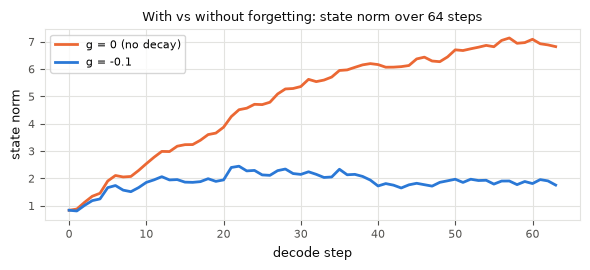

In [4]:
def step_norm_track(g_val, T=64, seed=2):
    torch.manual_seed(seed)
    K, V = 8, 8
    S = torch.zeros(V, K)
    norms = []
    for t in range(T):
        k = torch.nn.functional.normalize(torch.randn(K), dim=-1)
        v = torch.randn(V) * 0.3
        S = S * math.exp(g_val) + torch.outer(v, k)   # 简化版: 无 delta 项, 只看衰减
        norms.append(S.norm().item())
    return norms

n_free, n_decayed = step_norm_track(0.0), step_norm_track(-0.10)
print(f"无衰减   g=0:    ‖S‖ 64 步后 = {n_free[-1]:8.1f}  (线性膨胀)")
print(f"有衰减 g=-0.10: ‖S‖ 64 步后 = {n_decayed[-1]:8.1f}  (有界)")

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
PALETTE = ["#2a78d6", "#eb6834"]
fig, ax = plt.subplots(figsize=(6.0, 2.8))
ax.plot(range(64), n_free, color=PALETTE[1], lw=2, label="g = 0 (no decay)")
ax.plot(range(64), n_decayed, color=PALETTE[0], lw=2, label="g = -0.1")
ax.set_xlabel("decode step", fontsize=9, color="#0b0b0b")
ax.set_ylabel("state norm", fontsize=9, color="#0b0b0b")
ax.set_title("With vs without forgetting: state norm over 64 steps", fontsize=9, color="#0b0b0b")
ax.grid(True, color="#e3e3e0", lw=0.8)
for s in ax.spines.values(): s.set_color("#e3e3e0")
ax.tick_params(colors="#52514e", labelsize=8)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. 真实规模: 状态是显存大户 (量化的动机)

真实模型 (如 Qwen3.5-0.8B 的 GDN 层, 单卡): 每层有 $H=8$ 个头, 每头账本是 $128\times128$ 的
fp32 矩阵; 引擎还要为**每个并发请求槽位**各存一份。算一下这笔账:

In [5]:
H, V, K = 8, 128, 128
per_head = V * K * 4                       # fp32 = 4 字节
print(f"每头状态   : {V}×{K} × 4B = {per_head/1024:.0f} KB")
print(f"每层 (H={H}) : {per_head*H/1024:.0f} KB")
print()
print(f"{'槽位数':>6} | {'24 层':>10} | {'48 层':>10}")
for slots in (8, 32, 64):
    gb24 = per_head * H * 24 * slots / 2**30
    gb48 = per_head * H * 48 * slots / 2**30
    print(f"{slots:>6} | {gb24:>8.2f} GB | {gb48:>8.2f} GB")
print("\n→ 状态是纯 fp32 时, 几十 GB 显存就耗在'账本'上了")
print("→ 压到 int8 (÷4) 是最直接的省法, 问题只剩一个: 误差怎么控 — 下一本")

每头状态   : 128×128 × 4B = 64 KB
每层 (H=8) : 512 KB

   槽位数 |       24 层 |       48 层
     8 |     0.09 GB |     0.19 GB
    32 |     0.38 GB |     0.75 GB
    64 |     0.75 GB |     1.50 GB

→ 状态是纯 fp32 时, 几十 GB 显存就耗在'账本'上了
→ 压到 int8 (÷4) 是最直接的省法, 问题只剩一个: 误差怎么控 — 下一本


## 小结 (教程 1)

- 线性注意力把全部历史压进一个固定大小的矩阵状态 $S$ (账本), 每 token 更新一次;
- GDN 的账本会**衰减** ($g<0$, 否则范数发散) 和 **delta 改写** (写之前先修正账本误差);
- 状态在真实规模下是显存大户 → 想用 int8 压缩它。

→ **教程 2**: int8 量化是什么, 舍入误差从哪来, 以及"每步都量化"为什么会误差爆炸。